In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
from pathlib import Path

# Run from repo root. If you're elsewhere, uncomment and set this.
# os.chdir("/path/to/movebench")

# IMPORTANT: movebench uses MOVEBENCH_DATA_ROOT to find studies.
# Set this to the directory that contains a `studies/` folder.
# Example:
# os.environ["MOVEBENCH_DATA_ROOT"] = "/absolute/path/to/movebench_data"

repo_root = Path.cwd().resolve()
sys.path.insert(0, str(repo_root))

print("repo_root:", repo_root)
print("MOVEBENCH_DATA_ROOT:", os.environ.get("MOVEBENCH_DATA_ROOT"))

repo_root: /data/vision/beery/scratch/justin/movebench/notebooks
MOVEBENCH_DATA_ROOT: None


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from movebench.study import Study
from movebench.layers import REGISTRY

In [ ]:
# Study to inspect
study_id = "Ilyashenko_e82ecc51_raw_merged" #"Latham_c0de801a_raw_merged" #"Accio_967b7813_raw_merged" 
config_path = "../configs/layers_all_ae_1h_1h.yaml" # native.yaml"

study = Study(study_id)
print("study_dir:", study.study_dir)
print("trajectories_path:", study.trajectories_path)

study_dir: /archive/vision/beery/movebench/studies/Latham_c0de801a_raw_merged
trajectories_path: /archive/vision/beery/movebench/studies/Latham_c0de801a_raw_merged/trajectories.csv


In [5]:
df = pd.read_csv(study.trajectories_path)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.dropna(subset=["timestamp"])  # drop unparseable timestamps

print("rows:", len(df))
display(df.head())
print("splits:", sorted(df["set"].dropna().unique().tolist()))

rows: 8615


,event-id,visible,timestamp,location-long,location-lat,gps:dop,gps:fix-type,gps:satellite-count,sensor-type,individual-taxon-canonical-name,tag-local-identifier,individual-local-identifier,study-name,set,point_id
0,11952913778,True,2006-02-06 19:01:55,-113.385035,56.195053,4.2,3,6,gps,Canis lupus,1,1,Latham Alberta Wolves,train,0
1,11952913779,True,2006-02-07 01:01:49,-113.384463,56.191584,5.4,3,5,gps,Canis lupus,1,1,Latham Alberta Wolves,train,1
2,11952913780,True,2006-02-07 07:01:49,-113.385905,56.186144,3.2,3,5,gps,Canis lupus,1,1,Latham Alberta Wolves,train,2
3,11952913781,True,2006-02-07 13:00:54,-113.385206,56.185452,5.8,3,5,gps,Canis lupus,1,1,Latham Alberta Wolves,train,3
4,11952913782,True,2006-02-08 01:03:10,-113.361750,56.180404,3.4,2,4,gps,Canis lupus,1,1,Latham Alberta Wolves,train,4


splits: ['test', 'train']


In [6]:
plan = study.layer_plan(config_path)
print("layers:", len(plan.layers_in_order))
print("channels:", plan.num_channels())
print("chip_groups:", list(plan.chip_groups.keys()))
print("derived:", sorted(plan.derived_dependencies.keys()))

layers: 24
channels: 157
chip_groups: ['era5', 'high_res']
derived: ['aspect', 'landsat_bai', 'landsat_evi', 'landsat_lst', 'landsat_ndsi', 'landsat_ndvi', 'landsat_ndwi', 'orographic_uplift_hourly', 'rugosity', 'slope', 'thermal_uplift_hourly']


In [7]:
# If you haven't downloaded rasters yet, run this. (Requires Earth Engine auth + deps.)
# result = study.download_rasters(config=config_path, splits=["train", "test"], n_workers=8)
# result

In [8]:
io = study.layer_io(config_path)

# Pick a point to visualize.
row = df[df["set"] == "train"].iloc[100]
point_id = int(row["point_id"])
timestamp = row["timestamp"]
lon = float(row["location-long"])
lat = float(row["location-lat"])

print("point_id:", point_id)
print("timestamp:", timestamp)
print("lon/lat:", lon, lat)

point_id: 100
timestamp: 2006-02-22 19:01:43
lon/lat: -113.1618107 56.097943


In [9]:
def _robust_vmin_vmax(x: np.ndarray, p_lo=2, p_hi=98):
    x = x[np.isfinite(x)]
    if x.size == 0:
        return 0.0, 1.0
    return np.nanpercentile(x, [p_lo, p_hi]).tolist()


def plot_raster(r, title=None, max_bands=16, ncols=4, cmap="viridis", vmin=None, vmax=None):
    arr = np.asarray(r.array)
    C = arr.shape[0]
    C_show = min(C, max_bands)

    ncols = min(ncols, C_show)
    nrows = int(np.ceil(C_show / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 4 * nrows), squeeze=False)
    axes = axes.reshape(-1)

    for i in range(nrows * ncols):
        ax = axes[i]
        if i >= C_show:
            ax.axis("off")
            continue

        band = arr[i]
        vvmin, vvmax = (vmin, vmax)
        if vvmin is None or vvmax is None:
            vvmin, vvmax = _robust_vmin_vmax(band)

        im = ax.imshow(band, cmap=cmap, vmin=vvmin, vmax=vvmax)
        ax.set_title(r.band_ids[i])
        ax.axis("off")
        nan_frac = float(np.isnan(band).mean()) if np.issubdtype(band.dtype, np.floating) else 0.0
        ax.text(0.01, 0.01, f"NaN={nan_frac:.2f}", transform=ax.transAxes, color="w",
                bbox=dict(facecolor="k", alpha=0.35, pad=2))

    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def load_bounds_for_point(point_id: int):
    r = io.load_layer("landsat_lst", point_id=point_id)
    return tuple(map(float, r.bounds))


bounds_latlon = load_bounds_for_point(point_id)
print("bounds_latlon:", bounds_latlon)

bounds_latlon: (-113.4012156901328, 55.961728510046854, -112.92114526919451, 56.23260623359304)


## Visualize Downloaded GEE Chips

These are the per-point chip stacks written to:
`study_dir/rasters/<rasters_hash>/chips/<chip_group>/<point_id>.tif`.

Missing pixels are stored as `-9999` in the GeoTIFF and converted to `NaN` by `LayerIO`.

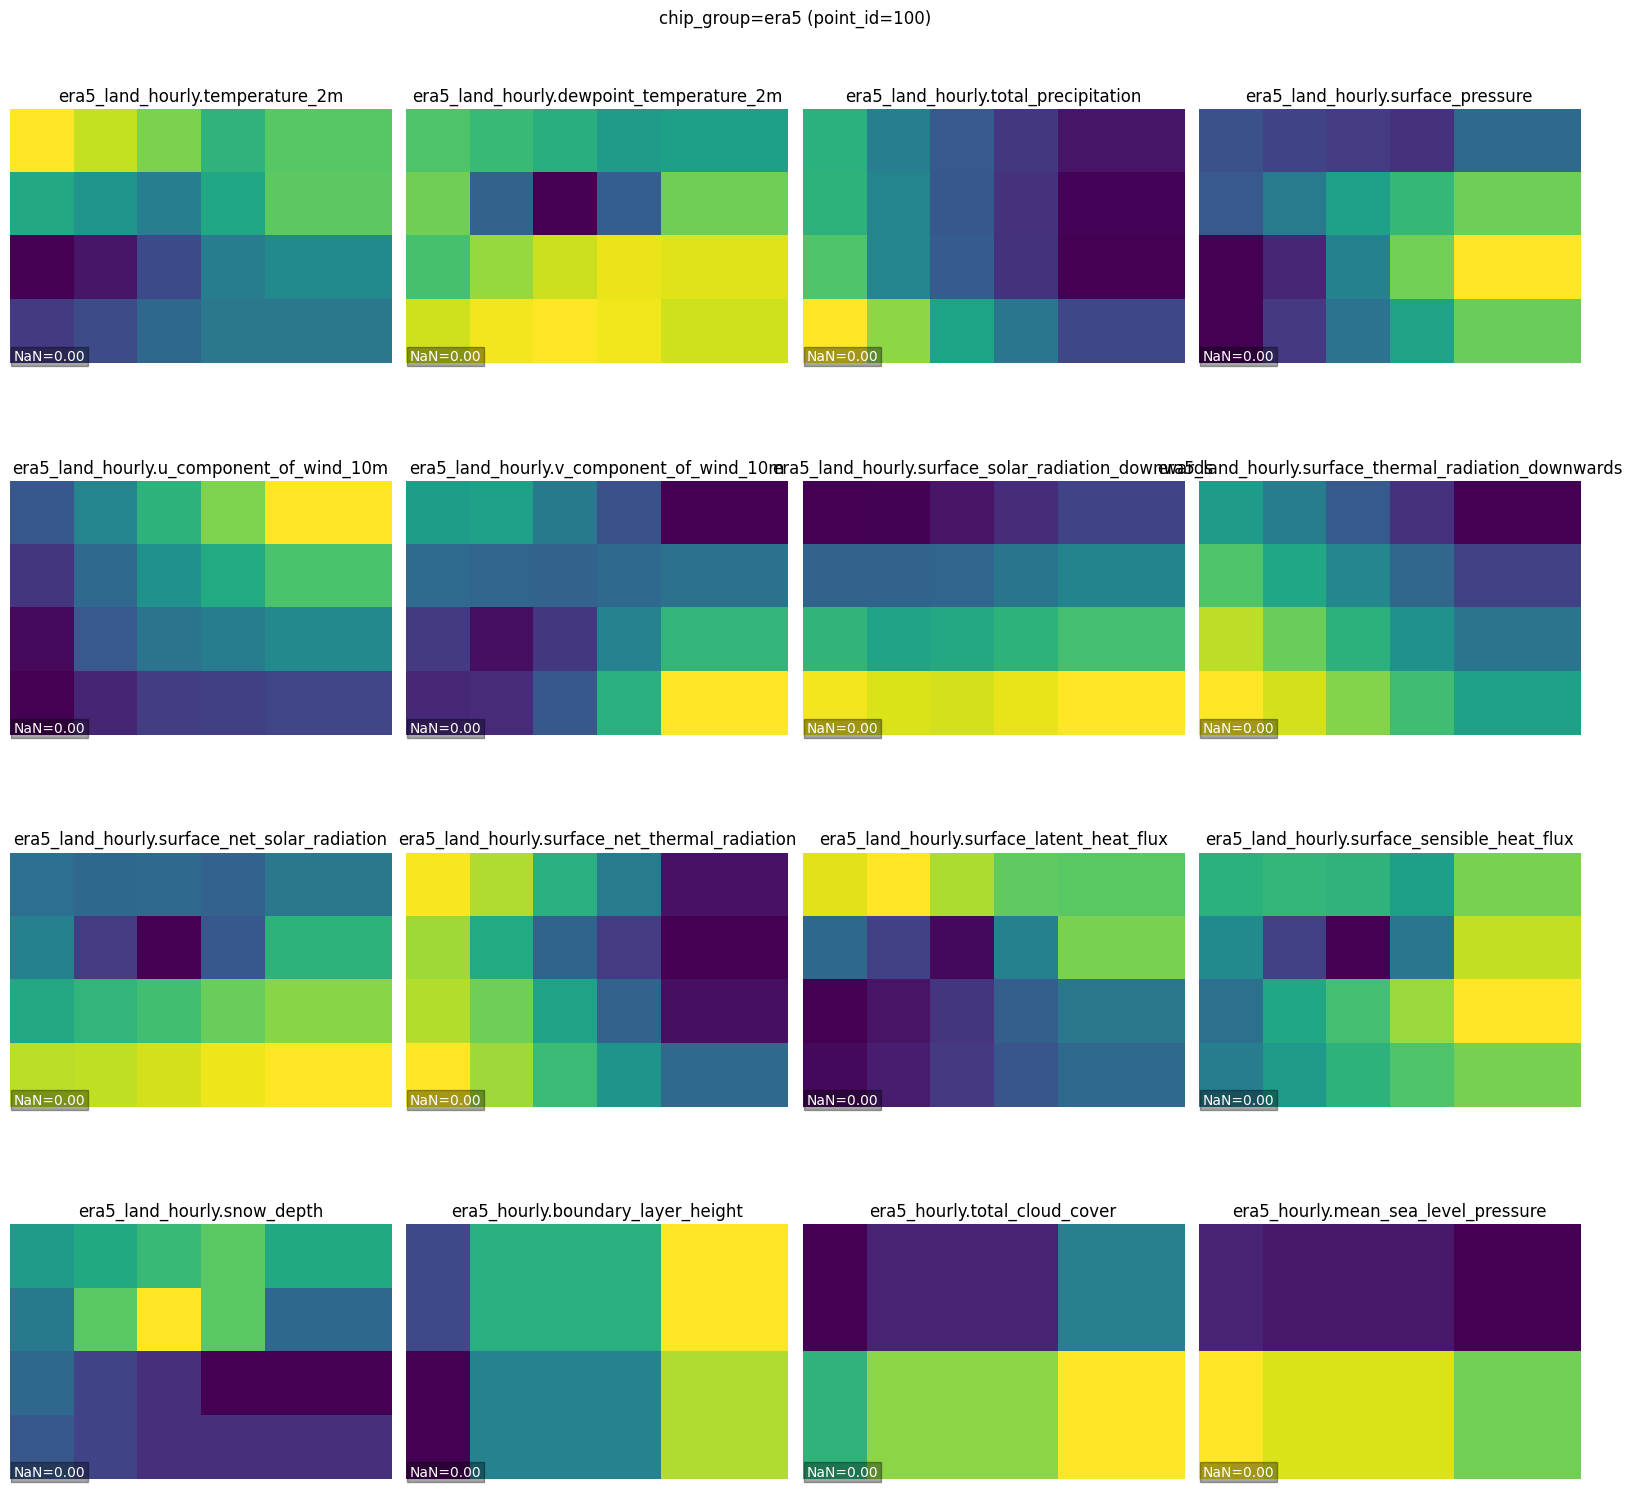

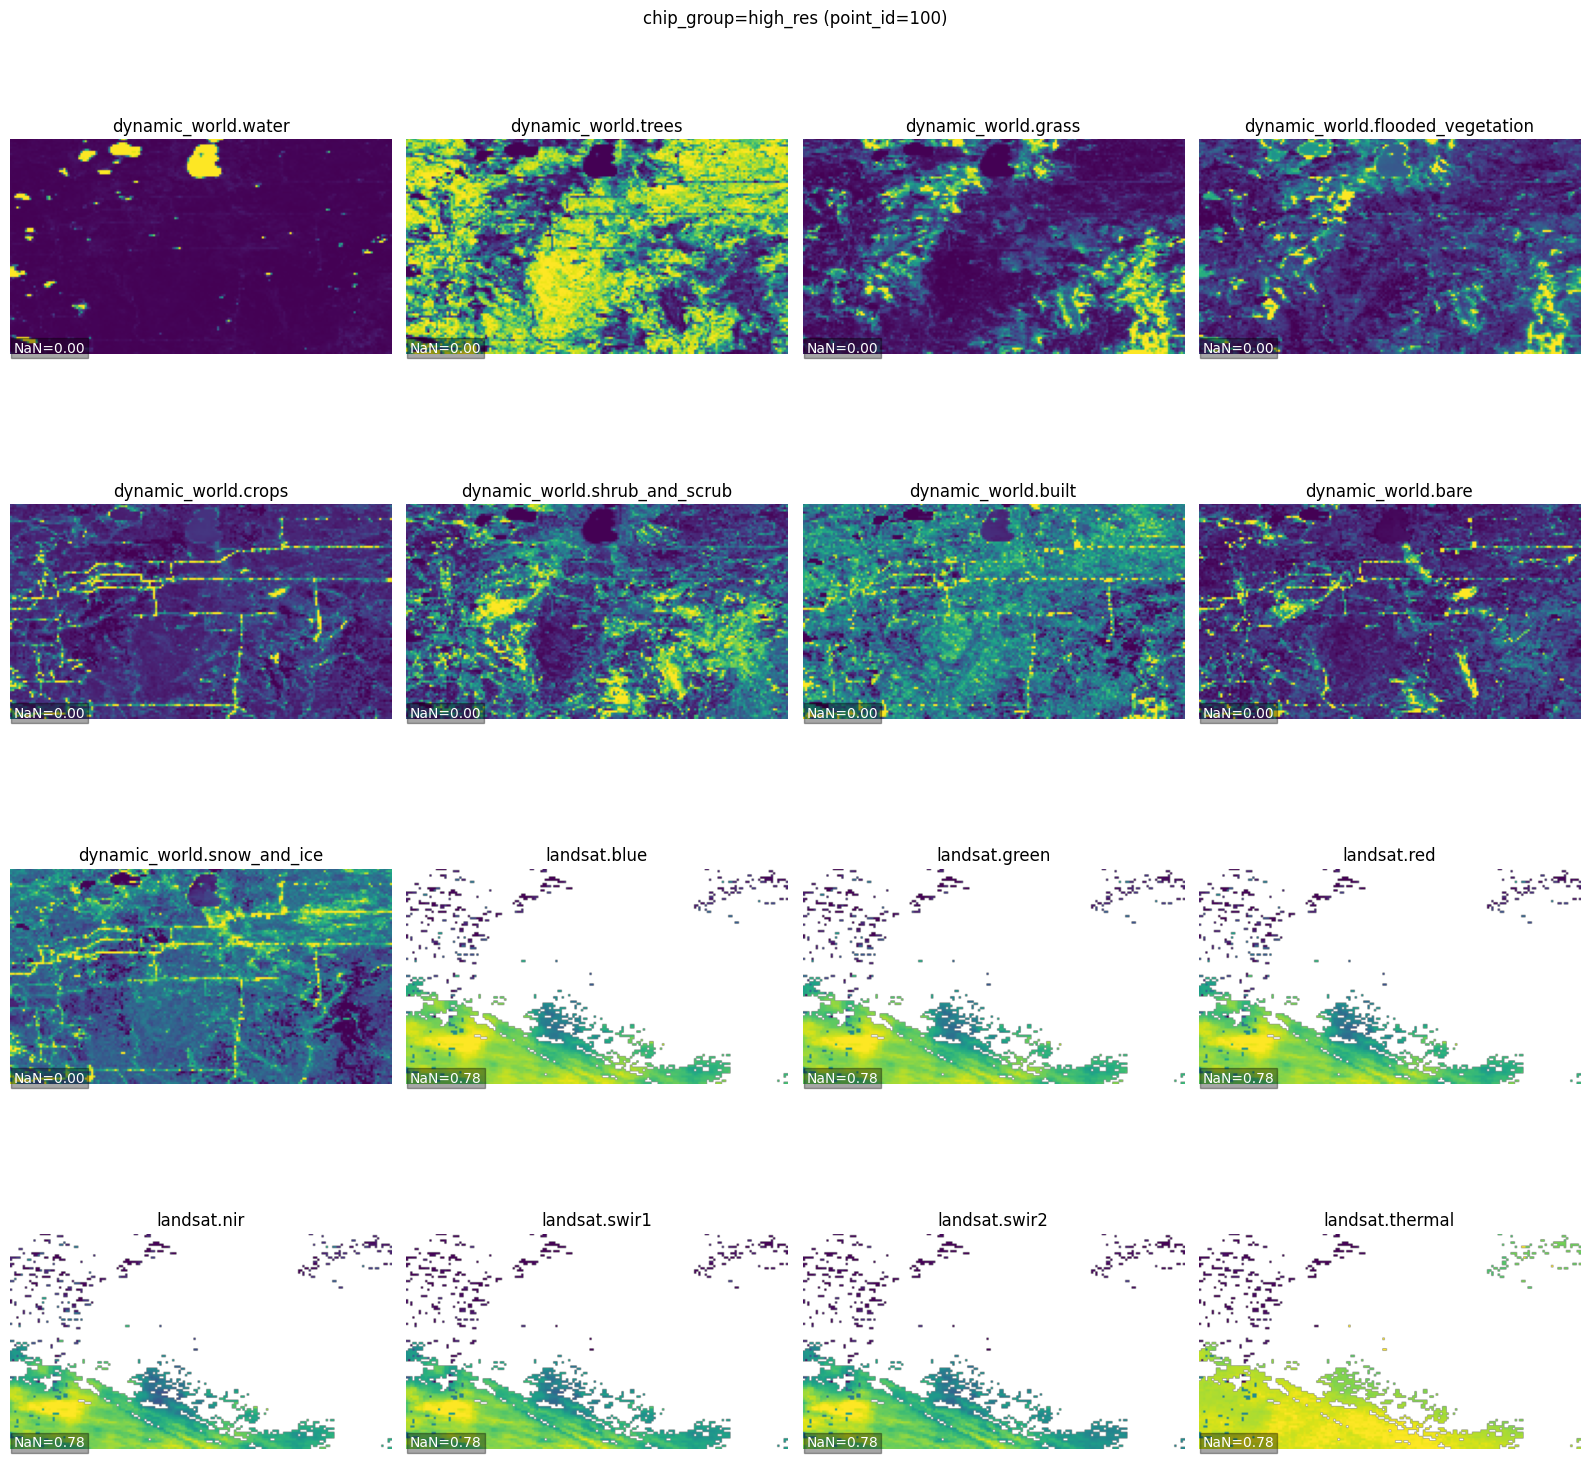

In [10]:
for group_name in plan.chip_groups.keys():
    # Access cached chip-group stack via the internal helper.
    r = io._load_gee_chip_group(group_name, point_id)
    plot_raster(r, title=f"chip_group={group_name} (point_id={point_id})", max_bands=16)

## Visualize Downloaded GEE Tiles

Tiles are stored as:
`study_dir/rasters/<rasters_hash>/tiles/<layer>/tile_XXX.tif` + `index.json`.

We load a window covering the chip bounds.

gee_tile_layers: ['modis_lc', 'modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg', 'dem', 'dist_water', 'alphaearth_embeddings']


/data/vision/beery/scratch/justin/movebench/movebench/layers/io.py:389: RuntimeWarning: Incomplete GEE tile index for layer='modis_lc': reported=5 effective=4 at /archive/vision/beery/movebench/studies/Latham_c0de801a_raw_merged/rasters/sm20-sq095-msq099-gq0999-mns6h-mxs6h-mnp3-mxp100-pps350/tiles/modis_lc/index_2006.json. Rerun downloads for this study.
  warnings.warn(


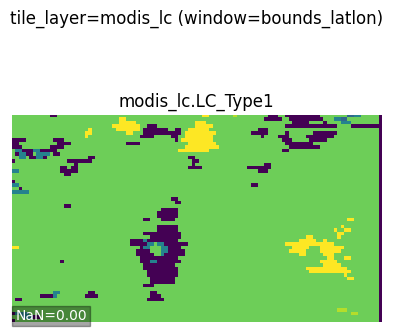

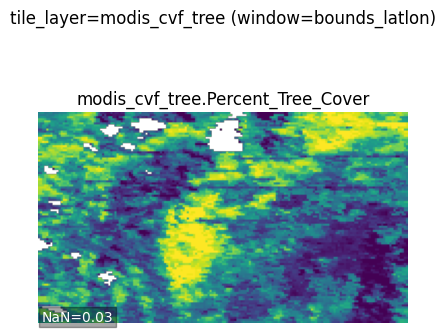

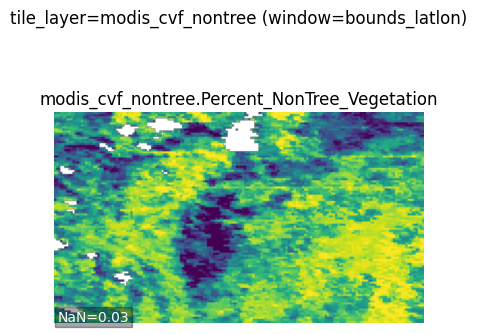

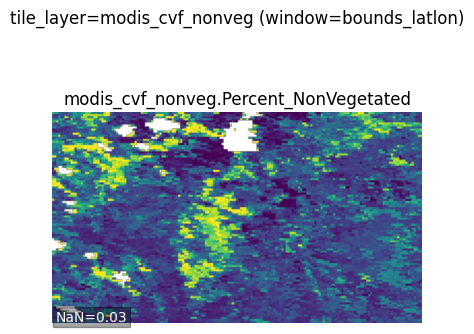

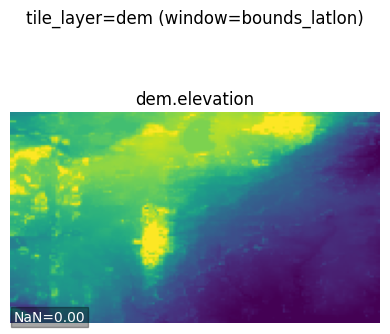

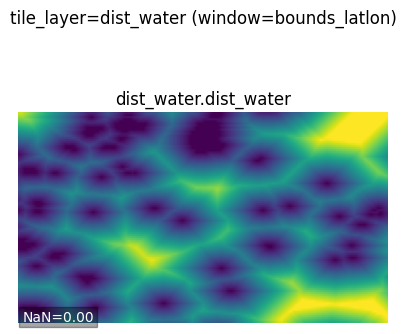

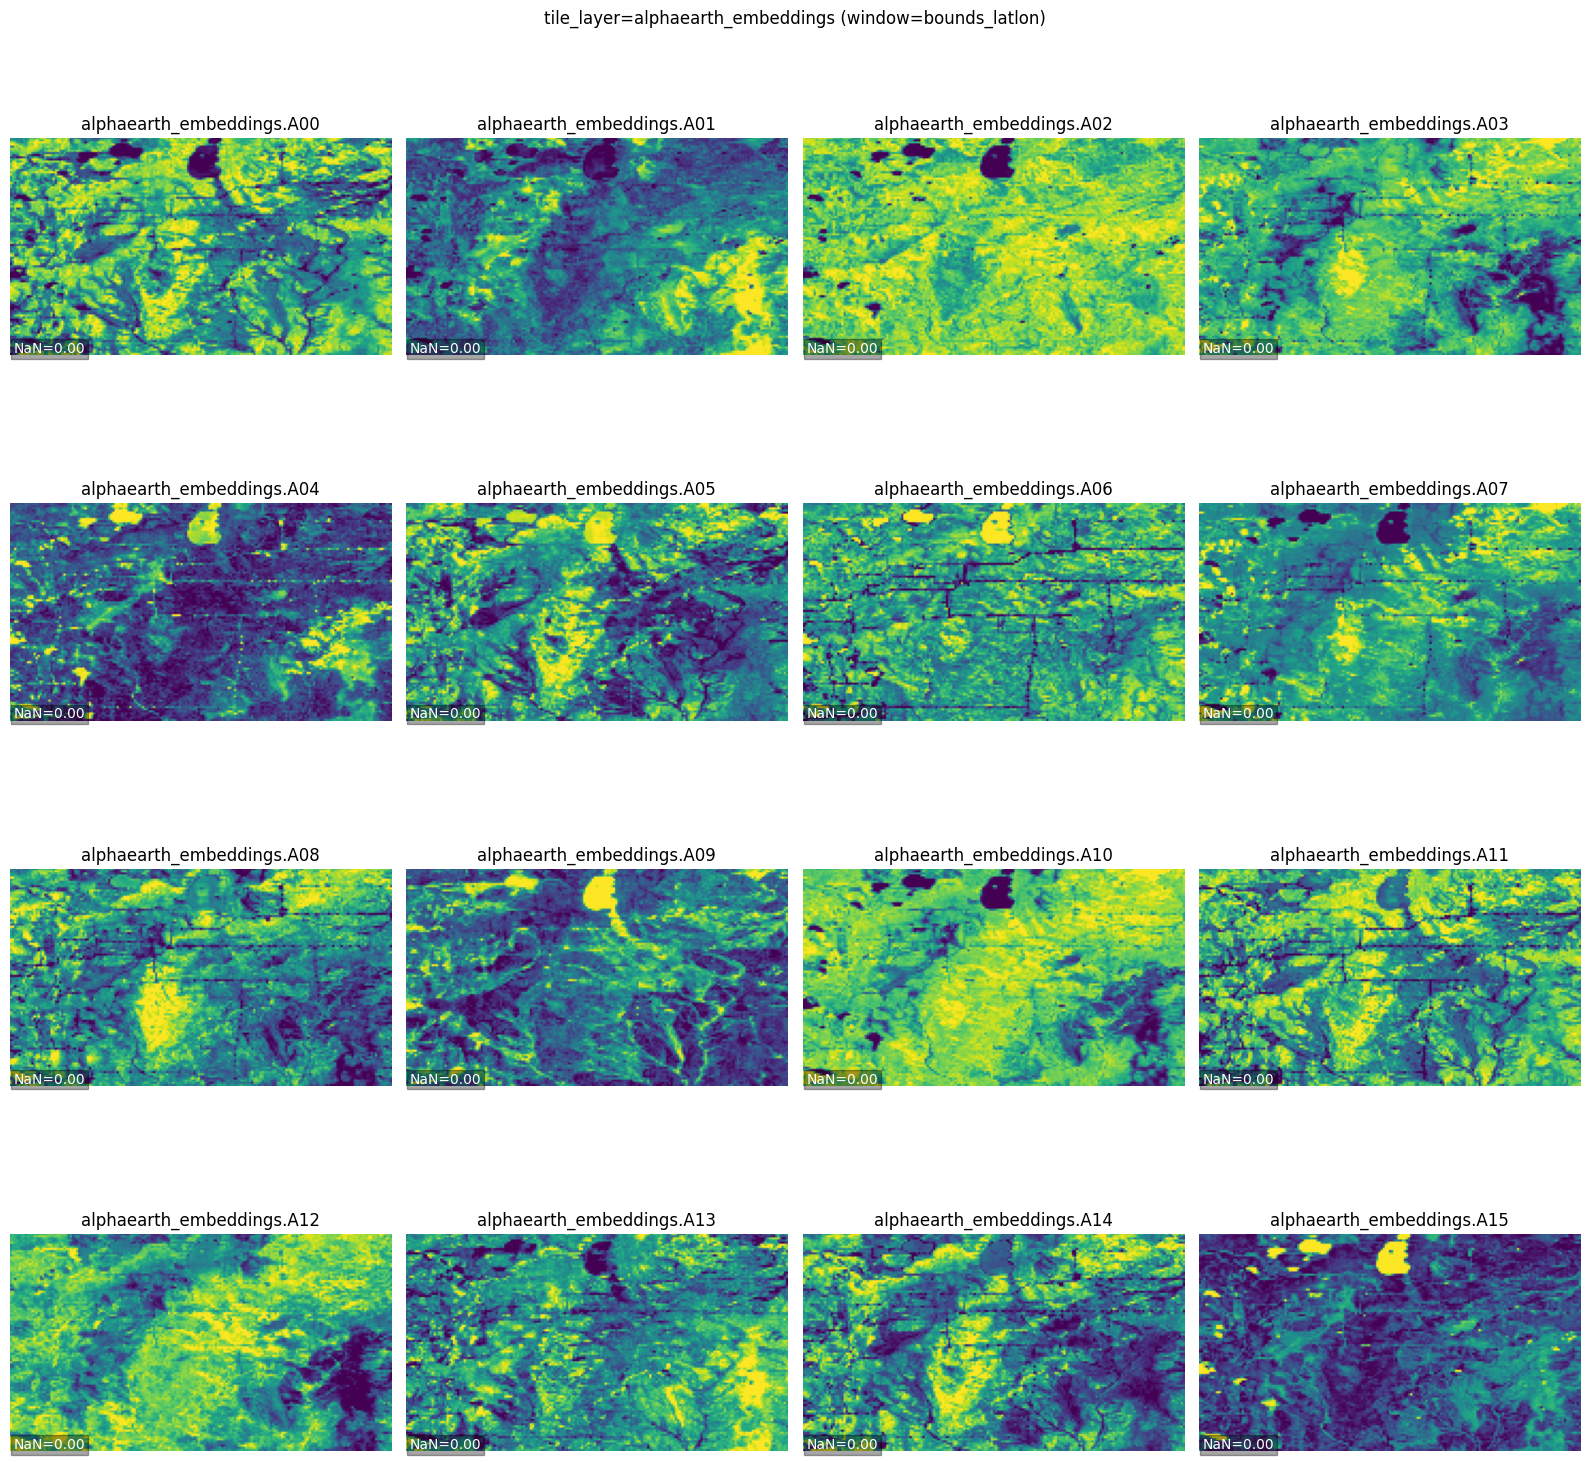

In [11]:
gee_tile_layers = [l for l in plan.layers_in_order if REGISTRY.get(l).source == "gee_tile"]
print("gee_tile_layers:", gee_tile_layers)

for layer in gee_tile_layers:
    r = io.load_layer(layer, 
                      bounds_latlon=bounds_latlon, 
                      timestamp=row["timestamp"] # use sample timestamp
                      )
    plot_raster(r, title=f"tile_layer={layer} (window=bounds_latlon)")

## Visualize Derived Layers

Derived layers are computed on-the-fly from parent rasters.
This checks that the needed chips/tiles exist and that the derived math runs.

derived_layers: ['landsat_ndvi', 'landsat_evi', 'landsat_ndwi', 'landsat_ndsi', 'landsat_bai', 'landsat_lst', 'slope', 'aspect', 'rugosity', 'orographic_uplift_hourly', 'thermal_uplift_hourly']


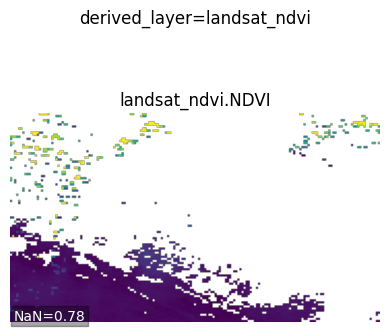

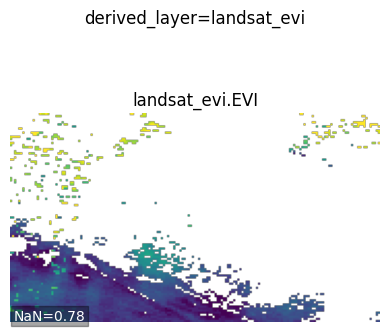

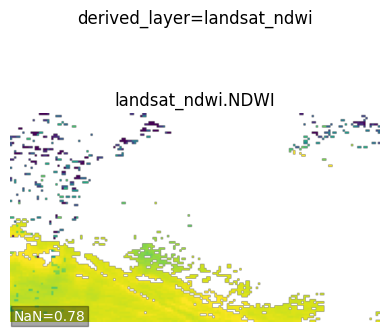

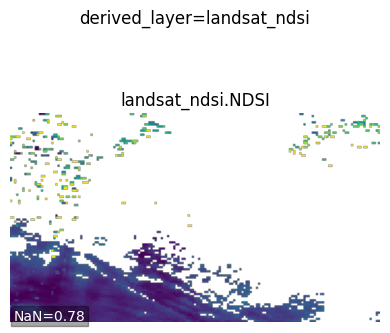

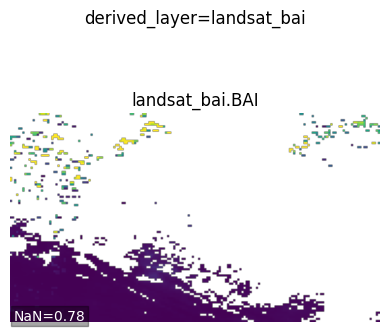

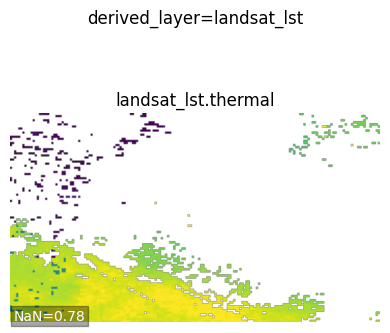

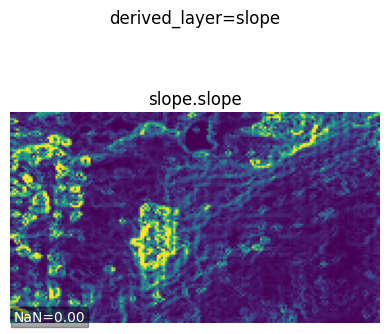

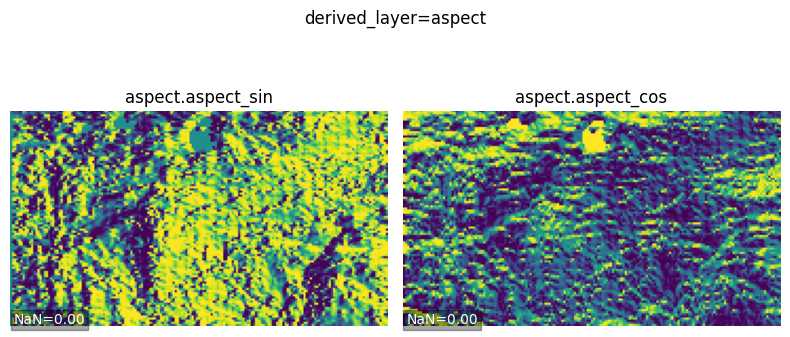

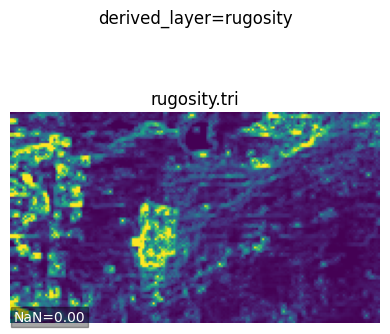

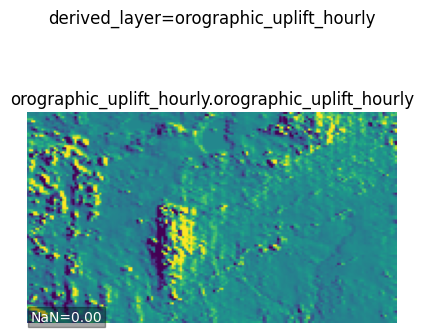

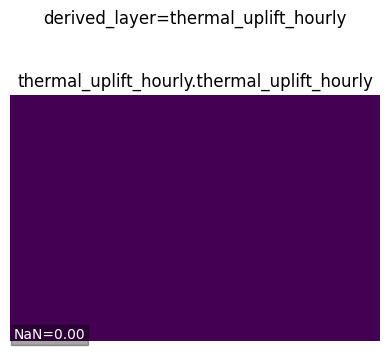

In [12]:
derived_layers = [l for l in plan.layers_in_order if REGISTRY.get(l).source == "derived"]
print("derived_layers:", derived_layers)

for layer in derived_layers:
    r = io.load_layer(layer, point_id=point_id, bounds_latlon=bounds_latlon, timestamp=timestamp)
    plot_raster(r, title=f"derived_layer={layer}")

## Plot Tile Coverage

Draw tile rectangles from `index.json` and overlay trajectory points.
This is useful to sanity-check the tile grid and extent.

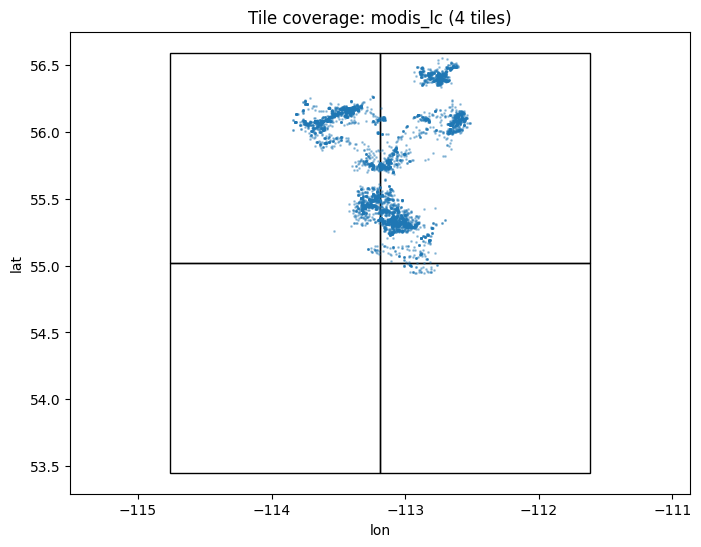

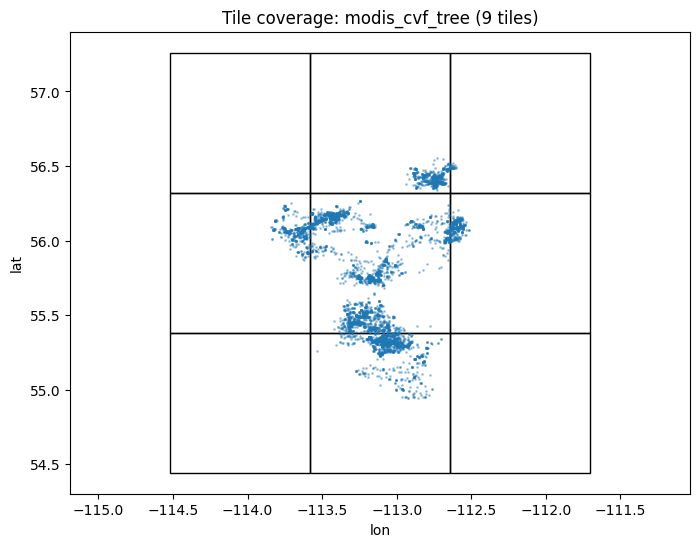

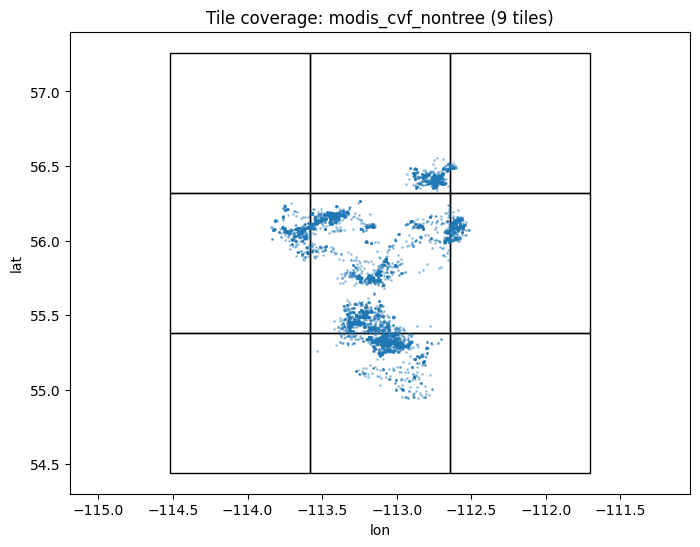

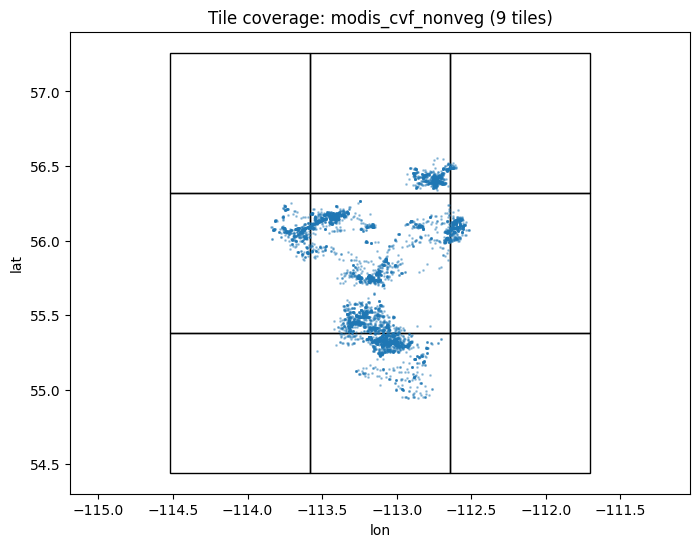

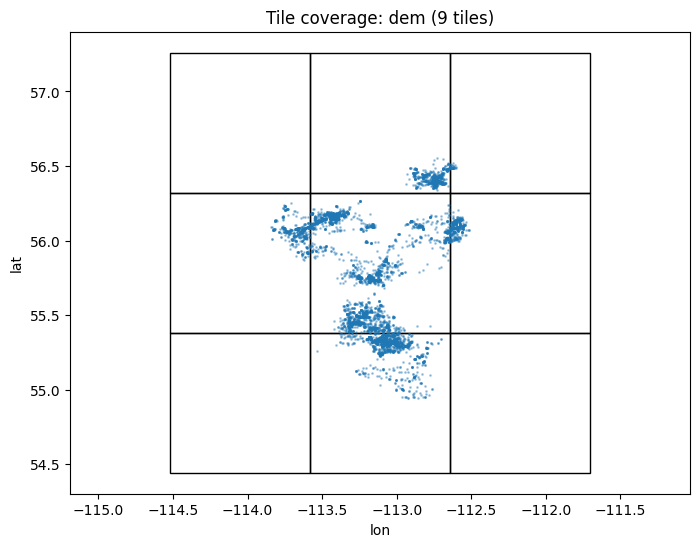

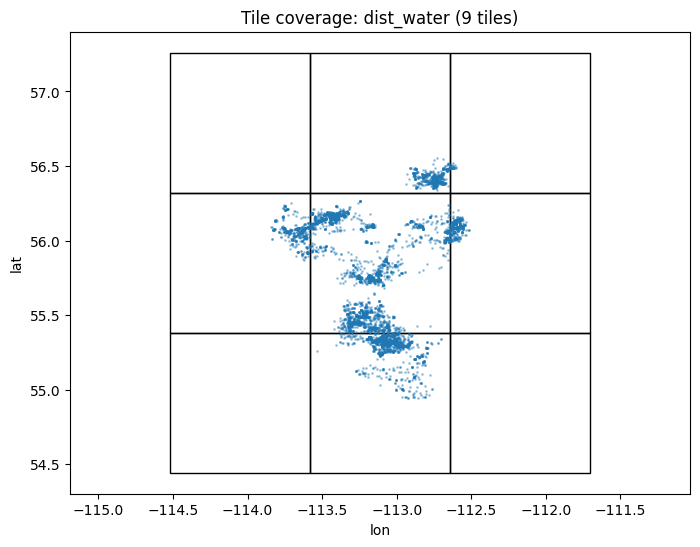

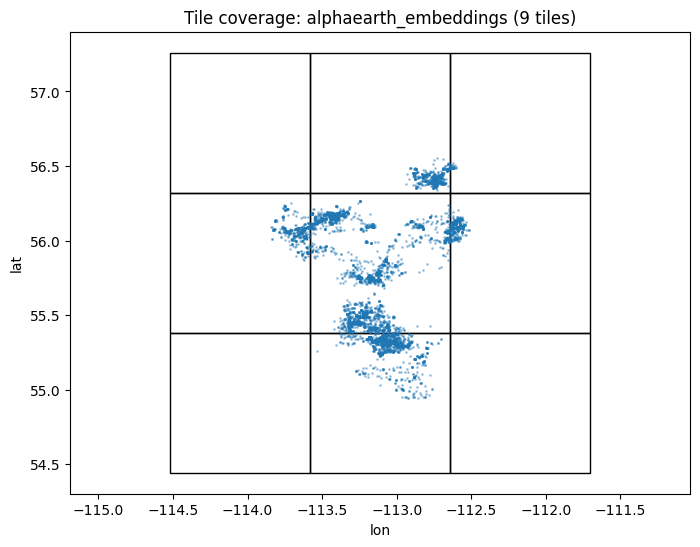

In [13]:
import json
from matplotlib.patches import Rectangle

rasters_root = study.study_dir / "rasters" / plan.rasters_hash

for layer in gee_tile_layers:
    index_path = rasters_root / "tiles" / layer / "index.json"
    if not index_path.exists():
        print("missing index.json:", index_path)
        continue
    idx = json.loads(index_path.read_text())
    tiles = idx.get("tiles", [])

    fig, ax = plt.subplots(1, 1, figsize=(8, 6))
    for t in tiles:
        b = t["bounds"]
        rect = Rectangle(
            (b["min_lon"], b["min_lat"]),
            b["max_lon"] - b["min_lon"],
            b["max_lat"] - b["min_lat"],
            fill=False,
            linewidth=1,
        )
        ax.add_patch(rect)

    ax.scatter(df["location-long"], df["location-lat"], s=1, alpha=0.35)
    ax.set_title(f"Tile coverage: {layer} ({len(tiles)} tiles)")
    ax.set_xlabel("lon")
    ax.set_ylabel("lat")
    ax.set_aspect("equal", adjustable="datalim")
    plt.show()